In [8]:
!pip install tensorflow;

In [9]:
import tensorflow as tf
print(tf.__version__)

2.19.0


In [11]:
# import basic libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [32]:
df = pd.read_csv("Churn_Modelling.csv")
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [47]:
# Divide the dataset into independent and dependent features
X = df.iloc[:, 3:13] # Don't keep RowNumber, CustomerId, or Surname as it won't be useful
y = df.iloc[:, 13] # Exited will be our label for classification

In [48]:
X.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,619,France,Female,42,2,0.00,1,1,1,101348.88
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58
2,502,France,Female,42,8,159660.80,3,1,0,113931.57
3,699,France,Female,39,1,0.00,2,0,0,93826.63
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10


In [49]:
y.head()

,Exited
0,1
1,0
2,1
3,0
4,0


In [50]:
# Feature Engineering: One-hot-encode categorical features (Geograph, Gender)
geography = pd.get_dummies(X['Geography'], drop_first=True, dtype="int")
gender = pd.get_dummies(X['Gender'], drop_first=True, dtype="int")

In [51]:
geography.head()

,Germany,Spain
0,0,0
1,0,1
2,0,0
3,0,0
4,0,1


In [52]:
gender.head()

,Male
0,0
1,0
2,0
3,0
4,0


In [53]:
# Drop current Geography and Gender columns in order to concatenate new OHE columns
X = X.drop(['Geography', 'Gender'], axis=1)
X = pd.concat([X, geography, gender], axis=1)

In [54]:
X.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Germany,Spain,Male
0,619,42,2,0.00,1,1,1,101348.88,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,1,0


In [55]:
# Split the dataset into training and test sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [58]:
# Feature scaling
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [73]:
print(f"Scaled X_train:\n\n{X_train}")
print(f"\nScaled X_test:\n\n{X_test}")

Scaled X_train:

[[ 0.35649971 -0.6557859   0.34567966 ... -0.57946723 -0.57638802
   0.91324755]
 [-0.20389777  0.29493847 -0.3483691  ...  1.72572313 -0.57638802
   0.91324755]
 [-0.96147213 -1.41636539 -0.69539349 ... -0.57946723  1.73494238
   0.91324755]
 ...
 [ 0.86500853 -0.08535128 -1.38944225 ... -0.57946723 -0.57638802
  -1.09499335]
 [ 0.15932282  0.3900109   1.03972843 ... -0.57946723 -0.57638802
   0.91324755]
 [ 0.47065475  1.15059039 -1.38944225 ...  1.72572313 -0.57638802
   0.91324755]]

Scaled X_test:

[[-0.57749609 -0.6557859  -0.69539349 ...  1.72572313 -0.57638802
   0.91324755]
 [-0.29729735  0.3900109  -1.38944225 ... -0.57946723 -0.57638802
   0.91324755]
 [-0.52560743  0.48508334 -0.3483691  ... -0.57946723  1.73494238
  -1.09499335]
 ...
 [ 0.81311987  0.77030065  0.69270405 ... -0.57946723 -0.57638802
  -1.09499335]
 [ 0.41876609 -0.94100321 -0.3483691  ... -0.57946723 -0.57638802
   0.91324755]
 [-0.24540869  0.00972116 -1.38944225 ...  1.72572313 -0.5763880

In [74]:
X_train.shape

(8000, 11)

In [76]:
# Create the Artificial Neural Network (ANN)
from tensorflow.keras.models import Sequential                  # For forwards and backwards propagation
from tensorflow.keras.layers import Dense                       # For creating neurons
from tensorflow.keras.layers import LeakyReLU, PReLU, ELU, ReLU # Activation Functions
from tensorflow.keras.layers import Dropout                     # Deactivate % of neurons during propagation in order to prevent overfitting

In [123]:
# Initialize ANN
classifier = Sequential()

In [124]:
# Add the input layer
classifier.add(Dense(units=11, activation='relu')) # 11 because there are 11 features as seen from X_train.shape

In [125]:
# Add the first hidden layer with a dropout layer
classifier.add(Dense(units=6, activation='relu')) # 6 neurons in first hidden layer
classifier.add(Dropout(0.2))

In [126]:
# Add the second hidden layer with a dropout layer
classifier.add(Dense(units=6, activation='relu')) # 6 neurons in second hidden layer
classifier.add(Dropout(0.3))

In [127]:
# Add the output layer
classifier.add(Dense(units=1, activation='sigmoid')) # Sigmoid activation function for binary classification

In [128]:
classifier.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [129]:
# Early Stopping
import tensorflow as tf
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    min_delta=0.0001,
    patience=20,
    verbose=1,
    mode="auto",
    baseline=None,
    restore_best_weights=False,
    start_from_epoch=0
)

In [130]:
model_history = classifier.fit(X_train, y_train, validation_split=0.33, batch_size=10, epochs=1000, callbacks=early_stopping)

Epoch 1/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - accuracy: 0.6187 - loss: 0.6815 - val_accuracy: 0.7914 - val_loss: 0.4982
Epoch 2/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7918 - loss: 0.5134 - val_accuracy: 0.8001 - val_loss: 0.4532
Epoch 3/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.8187 - loss: 0.4602 - val_accuracy: 0.8175 - val_loss: 0.4320
Epoch 4/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8190 - loss: 0.4472 - val_accuracy: 0.8243 - val_loss: 0.4225
Epoch 5/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8113 - loss: 0.4529 - val_accuracy: 0.8254 - val_loss: 0.4105
Epoch 6/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8236 - loss: 0.4312 - val_accuracy: 0.8326 - val_loss: 0.4002
Epoch 7/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8337 - loss: 0.4005 - val_accuracy: 0.8402 - val_loss: 0.3899
Epoch 8/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8415 - loss: 0.3925 - 

In [131]:
model_history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

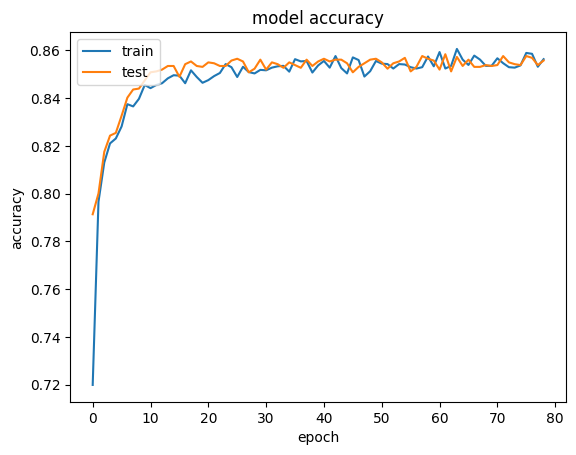

In [132]:
# Summarize history for accuracy
plt.plot(model_history.history['accuracy'])
plt.plot(model_history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

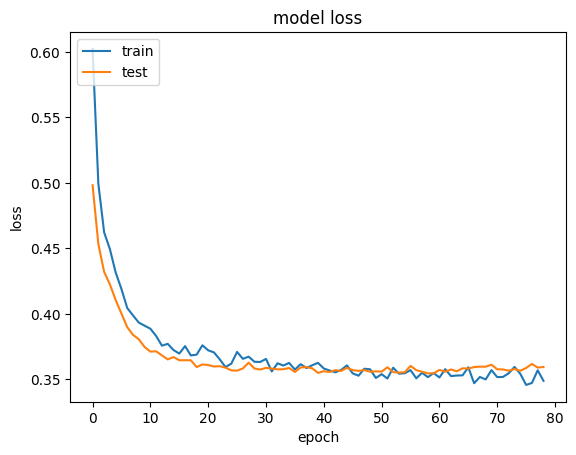

In [133]:
# Summarize history for loss
plt.plot(model_history.history['loss'])
plt.plot(model_history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

In [134]:
# Making the predictions and evaluating the model
y_pred = classifier.predict(X_test)
y_pred = (y_pred >= 0.5)

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step


In [135]:
# Make confusion matrix
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
print(f'Confusion Matrix:\n{cm}')

Confusion Matrix:
[[1549   58]
 [ 235  158]]


In [136]:
# Calculate the accuracy
from sklearn.metrics import accuracy_score
score = accuracy_score(y_pred, y_test)
print(f'Accuracy score: {score}')

Accuracy score: 0.8535
